# **Evaluación final — la solución, una sola vez, en el bloque final (Entregable 3, fase 4)**

Notebook del Entregable 3. **Es el único del repositorio autorizado a leer el bloque final** (2025-02-06 → 2025-12-31). Evalúa en
ese bloque, con el procedimiento fijado en la validación, la configuración elegida en la fase 3 (D42), su sensibilidad, su contraste y
las referencias. **No elige nada:** la solución quedó fijada en `experiments/modelos_candidatos/solucion_seleccionada.json` (commit
`1560a5b`) antes de abrir este bloque, y ninguna cifra de aquí puede cambiarla.

- **Código:** `src/modelo.py` (entrenamiento y predicción semanal, compartido con el prototipo), `src/variables.py`, `src/datos.py`.
  Las referencias (media constante, L0 y L1) son copia de las de `notebooks/modelos_candidatos.ipynb` (sección 6): siguen en el
  notebook y no en `src/`, deuda aceptada desde la review R1.
- **Artefactos:** `experiments/evaluacion_final/` — `tablas/`, `figuras/`, `predicciones_bloque_final.csv` (la usa el modo
  «Histórico» del prototipo) y `registro_ejecucion.csv` (la primera ejecución completa fija las métricas; toda reejecución tiene que
  reproducirlas exactamente).
- **Documento acompañante:** `documentacion/resumen_evaluacion_final.md`.
- **Estructura:** precisiones (D48, D50 a D52) → 0. Entorno → 1. Verificación de la solución fijada → 2. Procedimiento → 3. Control en
  validación (sin el bloque final) → **⛔ desde la sección 4 se lee el bloque final** → 4. Carga → 5. Evaluación → 6. Métricas →
  7. Análisis de errores → 8. Predicciones → 9. Registro de ejecución → 10. Cumplimiento de objetivos → 11. Figuras → 12. Índice.

## Precisiones de la evaluación final, fijadas antes de leer el bloque final (D48, D50, D51 y D52)

> **Nada de lo fijado en `notebooks/modelos_candidatos.ipynb` se modifica** (sección 1, adenda, precisiones de las fases 2 y 3, D42 a
> D45). Estas precisiones se escribieron **antes de ejecutar cualquier celda que lea el bloque final**. Lo que no esté acá ni en el JSON
> se decide antes de ejecutar, consultando al equipo; nunca después de ver resultados.

**D48 (20/10/2026)**

1. **Modelos.** *Solución:* GLM Poisson (a), ventana deslizante de 364 días. *Sensibilidad:* GLM Poisson (a), ventana expansiva; por D42
   **no puede reemplazar a la solución aunque gane en el test**. *Contraste:* XGBoost (a), `max_depth=2`, `n_estimators=100`,
   `learning_rate=0.1`, deslizante de 364 días; **no compite**. *Referencias:* media constante, L0 de 8 semanas y L1 (nivel del
   municipio × calendario de 8 niveles).
2. **Intervalos (D44).** En cada corte se ajusta también NB2 (a) con la ventana deslizante de 364 días, **solo para obtener α**; el
   intervalo usa μ de la solución y ese α. También se reportan los intervalos Poisson con la misma μ. El caso de no convergencia lo
   precisa D50.
3. Lo que no esté en estas precisiones ni en el JSON se decide antes de ejecutar, consultando al equipo.

**D50 (20/10/2026, respuestas del equipo al paso 4a; reemplaza a D48 solo en el fallback de NB2)**

1. **Reproducción de la fase 2** (`tests/test_modelo.py`): con tolerancia 1e-9 contra el camino de la fase 2 reconstruido dentro del test
   en los 47 cortes, y contra los artefactos guardados (`tablas/31`, `45` y `46` de `modelos_candidatos`) con la tolerancia del redondeo
   a 6 decimales.
2. **`entrenar(config, panel_hasta)`**: `panel_hasta` es el panel ya recortado a los días conocidos; el origen es el día siguiente al
   último. `src/modelo.py` no lee archivos.
3. **Fallback de NB2:** si NB2 no converge según D29, primero el **plan B de D28** (α por momentos en el mismo corte), igual que en
   validación; **solo si no da un α finito y positivo**, ese corte usa los intervalos Poisson. La fila se marca y el resumen informa
   cuántos cortes cayeron en cada caso.
4. **Calendario de los días a predecir:** `var.tipo_dia(fechas)` (`holidays` 0.103, Uruguay, categorías `public` y `bank`, como el ETL),
   solo para fechas que no están en el panel; si están, se usa el `tipo_dia` del panel.

**D51 (20/10/2026)**

1. **Intervalos solo para la solución**, como en validación: NB2 según D44 y D50 como principal, Poisson como secundario.
   Sensibilidad, contraste y referencias, **sin intervalos** (columnas vacías en `predicciones_bloque_final.csv`).
2. **Exportación local** (paso 4c) dentro de este notebook, **después de escribir `registro_ejecucion.csv`**.
   `train/train_modelo_final.py` es una **excepción declarada** a la regla de lectura del bloque final: entrena el modelo final y no
   evalúa.
3. **`models/historia_reciente.csv` queda fuera del alcance:** el conjunto (a) no usa nivel reciente ni rezagos.
4. Tolerancia de los tests contra `tablas/31`, `45` y `46`: **6e-7** (el redondeo a 6 decimales da hasta 5e-7; con 4,998e-7 medido, el
   test quedaba al borde del error de punto flotante).

**D52 (20/10/2026) — elecciones de análisis, fijadas antes de leer el bloque final** (propuestas por la IA y confirmadas por el equipo
el 20/10/2026, con dos ajustes, en los ítems 7 y 8)

1. **Cortes:** 47 de 7 días, orígenes 2025-02-06 + 7k (k = 0…46); el último horizonte termina el 2025-12-31. En cada corte, cada modelo
   se reentrena con **todo lo observado antes del origen** (desarrollo más las semanas ya transcurridas del bloque final) y su ventana:
   364 días para la solución y el contraste; expansiva para la sensibilidad y las tres referencias (como en validación). Hiperparámetros
   fijos (JSON). El objetivo de los días ≥ origen no llega a ningún modelo (vista con NaN, como en el motor de validación).
2. **Control previo, sin el bloque final:** el mismo procedimiento, aplicado a los 47 cortes de validación con
   `cargar_panel_desarrollo()`, tiene que reproducir `tablas/05`, `08`, `26`, `45` y `46` de `modelos_candidatos` (tolerancia 6e-7). Si
   no, la ejecución se detiene antes de leer el bloque final.
3. **Métricas:** las de validación (desvianza de Poisson media con EPS = 1e-6, error estándar sobre los 47 cortes, MAE, RMSE, total
   pred./obs., días con predicción 0, desvío entre cortes, peor municipio), globales, por municipio y por corte.
4. **Comparaciones:** cada candidato contra **L1** (la referencia de su mismo conjunto de información: los tres usan municipio y
   calendario), contra la **media constante** y contra **su propio desempeño en validación** (`tablas/26` para los candidatos, `05` y `08`
   para las referencias). L0 se compara con la media constante. Diferencia de desvianza y cortes ganados; además, la diferencia pareada
   corte a corte (media, EE y cortes ganados) para solución − L1, sensibilidad − L1, contraste − L1, solución − sensibilidad y solución −
   media constante, **descriptiva, como D35: no es una prueba de significación**.
5. **Análisis:** errores por municipio y por tipo de día (8 niveles) para solución, sensibilidad, contraste y L1; las 5 semanas de mayor
   desvianza de la solución con sus días; calibración por deciles de la predicción (solución y sensibilidad); residuos por corte con su
   tendencia (MCO, EE HAC de Newey-West con 4 rezagos) y observado/predicho por mitades (cortes 1–23 y 24–47); cobertura de los
   intervalos NB2 y Poisson, global y por municipio, con la esperada por el propio modelo. Los mismos cálculos que en validación
   (secciones 11 y 12 de `modelos_candidatos`).
6. **`predicciones_bloque_final.csv`:** una fila por (modelo, fecha, municipio): `fecha`, `origen`, `corte`, `municipio`, `observado`,
   `predicho`, `inf_80`, `sup_80`, `inf_95`, `sup_95`, `tipo_intervalo`, `modelo`, `papel`. Intervalos principales (NB2 según D50) solo
   en la solución; los Poisson secundarios quedan en la tabla de cobertura.
7. **`registro_ejecucion.csv`:** una fila por modelo con fecha y hora de la primera ejecución, `commit` (el HEAD), `arbol_limpio` y las
   métricas globales (más coberturas y conteo de cortes por origen de α para la solución), con precisión completa. Si el archivo existe, se
   recalcula, se comprueba que cada métrica coincide con **tolerancia relativa de 1e-10** (diferencias de punto flotante entre máquinas
   o hilos de BLAS) y no se reescribe; si difiere, la ejecución se detiene.
8. **Cumplimiento de los objetivos (1.2.2 del informe):** el informe no fija umbrales numéricos de éxito, así que **ningún estado depende
   de una cifra del bloque final**: el estado se fija acá, por el procedimiento. La tabla lleva **además los resultados del bloque final
   como evidencia** (por ejemplo, la desvianza de la solución contra L1), sin que cambien el estado. Objetivo 1 (ETL): cumplido en el E2. Objetivo 2 (estrategias con y sin exógenas, expansiva y deslizante): cumplido en
   calendario y ventanas, **no** en meteorología (conjunto (d) retirado antes de ejecutar). Objetivo 3 (seleccionar el modelo con mejor
   desempeño y solidez, con limitaciones): cumplido en el procedimiento, **con la salvedad de D42** (la final no es la que eligió la
   regla). Objetivo 4 (pestaña del dashboard): no cumplido en esta fase (fase 5).

## 0. Entorno

Igual que `modelos_candidatos.ipynb`: lee `requirements.txt` en vivo y **detiene la ejecución** si la versión de Python o la de alguna
dependencia directa difiere.

In [1]:
# Detiene la ejecución si el entorno no coincide con requirements.txt. No es un aviso.
import platform
import re
from pathlib import Path
import importlib.metadata as importlib_metadata

_cwd = Path.cwd()
if (_cwd / "requirements.txt").exists():
    _RAIZ_CHK = _cwd
elif (_cwd.parent / "requirements.txt").exists():
    _RAIZ_CHK = _cwd.parent
else:
    raise FileNotFoundError("No se encuentra requirements.txt para verificar el entorno.")

_req_texto = (_RAIZ_CHK / "requirements.txt").read_text(encoding="utf-8")

_m_py = re.search(r"#\s*Python\s+(\d+\.\d+\.\d+)", _req_texto)
if not _m_py:
    raise RuntimeError("No se encontró la versión de Python esperada en requirements.txt.")
PYTHON_ESPERADO = _m_py.group(1)

DEPENDENCIAS_ESPERADAS = {}
for _linea in _req_texto.splitlines():
    _sin_comentario = _linea.split("#", 1)[0].strip()
    _m = re.match(r"^([A-Za-z0-9_.\-]+)==([A-Za-z0-9_.\-]+)$", _sin_comentario)
    if _m:
        DEPENDENCIAS_ESPERADAS[_m.group(1).lower()] = _m.group(2)

python_actual = platform.python_version()
_errores = []
if python_actual != PYTHON_ESPERADO:
    _errores.append(f"Python: se esperaba {PYTHON_ESPERADO}, hay {python_actual}")

for _paquete, _version_esperada in DEPENDENCIAS_ESPERADAS.items():
    try:
        _version_actual = importlib_metadata.version(_paquete)
    except importlib_metadata.PackageNotFoundError:
        _errores.append(f"{_paquete}: no está instalado (se esperaba {_version_esperada})")
        continue
    if _version_actual != _version_esperada:
        _errores.append(f"{_paquete}: se esperaba {_version_esperada}, hay {_version_actual}")

if _errores:
    _mensaje = ("El entorno no coincide con requirements.txt (instalar con "
                "`pip install -r requirements.txt -c requirements-lock.txt`):\n  - "
                + "\n  - ".join(_errores))
    raise RuntimeError(_mensaje)

print(f"Entorno OK — Python {python_actual}, {len(DEPENDENCIAS_ESPERADAS)} dependencias "
      f"directas verificadas contra requirements.txt (ninguna diferencia).")

Entorno OK — Python 3.13.2, 18 dependencias directas verificadas contra requirements.txt (ninguna diferencia).


## Importación de librerías y configuración

In [2]:
import sys
import json
import hashlib
import subprocess
import warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn
import statsmodels
import statsmodels.api as sm
import xgboost
from sklearn.metrics import mean_poisson_deviance, mean_absolute_error, mean_squared_error

# Mismo aviso y mismo motivo que en pytest.ini: lo emite pandas 2.3.3 con numpy 2.5.2 en cada pd.Timedelta.
warnings.filterwarnings("ignore", message="The .generic. unit for NumPy timedelta", category=DeprecationWarning)

RAIZ = _RAIZ_CHK
sys.path.insert(0, str(RAIZ))
from src import datos, modelo as mod, variables as var      # única implementación de carga, variables y modelo

SEMILLA = 20260910      # la de modelos_candidatos.ipynb (el contraste la toma del JSON)
np.random.seed(SEMILLA)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

DIR_EXPERIMENTO = RAIZ / "experiments" / "evaluacion_final"
DIR_TABLAS = DIR_EXPERIMENTO / "tablas"
DIR_FIGURAS = DIR_EXPERIMENTO / "figuras"
DIR_TABLAS.mkdir(parents=True, exist_ok=True)
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
DIR_VALIDACION = RAIZ / "experiments" / "modelos_candidatos"
TABLAS_VALIDACION = DIR_VALIDACION / "tablas"


def guardar_tabla(df, nombre):
    "Escribe un CSV (UTF-8) en experiments/evaluacion_final/tablas y devuelve el DataFrame."
    ruta = DIR_TABLAS / nombre
    df.to_csv(ruta, index=False, encoding="utf-8")
    print("  guardado:", ruta.relative_to(RAIZ), f"({len(df)} filas)")
    return df


def guardar_figura(fig, nombre):
    ruta = DIR_FIGURAS / nombre
    fig.savefig(ruta, bbox_inches="tight")
    print("  guardado:", ruta.relative_to(RAIZ))


def leer_validacion(nombre):
    return pd.read_csv(TABLAS_VALIDACION / nombre, encoding="utf-8")


entorno = pd.DataFrame({
    "componente": ["python", "pandas", "numpy", "scipy", "matplotlib", "scikit-learn", "statsmodels", "xgboost"],
    "version": [python_actual, pd.__version__, np.__version__, scipy.__version__, matplotlib.__version__,
                sklearn.__version__, statsmodels.__version__, xgboost.__version__],
})
guardar_tabla(entorno, "00_entorno.csv")

  guardado: experiments\evaluacion_final\tablas\00_entorno.csv (8 filas)


,componente,version
0,python,3.13.2
1,pandas,2.3.3
2,numpy,2.5.2
3,scipy,1.18.1
4,matplotlib,3.11.1
5,scikit-learn,1.9.0
6,statsmodels,0.14.6
7,xgboost,3.4.1


## 1. La solución fijada: verificación con git

El JSON de la fase 3 se identifica por `git log` del archivo (`1560a5b`), **no** por su campo `commit_del_repositorio`, que dice `5f207e2`
(limitación (c) de `resumen_modelos_candidatos.md` §5; D46). Se verifica que el archivo tiene ese único commit, que el del árbol de trabajo es
idéntico al de ese commit, que ese commit es antecesor de HEAD y que todo commit de este notebook es posterior a él. **Si algo falla, la
ejecución se detiene.** Después se comprueba que las tres configuraciones del JSON son las de D48.

In [3]:
COMMIT_FASE3 = "1560a5b"
RUTA_JSON = DIR_VALIDACION / "solucion_seleccionada.json"
REL_JSON = RUTA_JSON.relative_to(RAIZ).as_posix()
REL_NB = "notebooks/evaluacion_final.ipynb"


def git(*args):
    return subprocess.run(["git", *args], cwd=RAIZ, capture_output=True, text=True, check=True).stdout.strip()


def es_antecesor(a, b):
    return subprocess.run(["git", "merge-base", "--is-ancestor", a, b], cwd=RAIZ).returncode == 0


commit_fase3 = git("rev-parse", COMMIT_FASE3)
commits_json = git("log", "--format=%H", "--", REL_JSON).split()
commits_nb = git("log", "--format=%H", "--", REL_NB).split()
fijado = json.loads(RUTA_JSON.read_text(encoding="utf-8"))
verif_json = pd.DataFrame([
    ("el JSON tiene un único commit en la historia, y es 1560a5b", commits_json == [commit_fase3]),
    ("el JSON del árbol de trabajo es idéntico al de 1560a5b", git("diff", commit_fase3, "--", REL_JSON) == ""),
    ("1560a5b es antecesor de HEAD", es_antecesor(commit_fase3, "HEAD")),
    ("todo commit de este notebook es posterior a 1560a5b",
     all(c != commit_fase3 and es_antecesor(commit_fase3, c) for c in commits_nb)),
    ("el JSON declara bloque_final_leido = false", fijado["bloque_final_leido"] is False),
    ("decisión D42", fijado["decision"] == "D42"),
], columns=["verificación", "ok"])
print(verif_json.to_string(index=False))
print("commits de este notebook antes de esta ejecución:", len(commits_nb))
assert verif_json["ok"].all(), "solucion_seleccionada.json cambió o no es el de la fase 3: DETENERSE y consultar."
guardar_tabla(verif_json, "01_verificacion_solucion_fijada.csv")

CFG = {papel: mod.cargar_configuracion(papel, RUTA_JSON) for papel in ("solucion", "sensibilidad", "contraste")}
COLS_A = ["mun_" + z.removeprefix("MUNICIPIO ") for z in mod.MUNICIPIOS] + ["cal_" + n for n in var.NIVELES_CALENDARIO[1:]]
assert all(c["conjunto_de_variables"]["columnas"] == COLS_A for c in CFG.values())
assert CFG["solucion"]["modelo"] == "GLM" and CFG["solucion"]["ventana"] == {"tipo": "deslizante", "dias": 364}
assert CFG["sensibilidad"]["modelo"] == "GLM" and CFG["sensibilidad"]["ventana"] == {"tipo": "expansiva", "dias": None}
assert CFG["contraste"]["modelo"] == "XGBoost" and CFG["contraste"]["ventana"] == {"tipo": "deslizante", "dias": 364}
assert {k: CFG["contraste"]["hiperparametros"][k] for k in ("max_depth", "n_estimators", "learning_rate")} == \
    {"max_depth": 2, "n_estimators": 100, "learning_rate": 0.1}
EPS = fijado["eps_desvianza"]
assert EPS == 1e-6
for papel, c in CFG.items():
    print(f"{papel:>12}: {c['configuracion']}")

                                              verificación   ok
el JSON tiene un único commit en la historia, y es 1560a5b True
    el JSON del árbol de trabajo es idéntico al de 1560a5b True
                              1560a5b es antecesor de HEAD True
       todo commit de este notebook es posterior a 1560a5b True
                el JSON declara bloque_final_leido = false True
                                              decisión D42 True
commits de este notebook antes de esta ejecución: 1
  guardado: experiments\evaluacion_final\tablas\01_verificacion_solucion_fijada.csv (6 filas)
    solucion: GLM Poisson (a) [deslizante 364 d]
sensibilidad: GLM Poisson (a) [expansiva]
   contraste: XGBoost (a) d=2 n=100 lr=0.1 [deslizante 364 d]


## 2. Procedimiento

El mismo de la validación (sección 3 de `modelos_candidatos`): origen móvil, reentrenamiento en cada corte, horizonte de 7 días. En cada
corte, cada modelo recibe una **vista** del panel hasta el último día del horizonte con el objetivo de los días ≥ origen en NaN. Los tres
candidatos se entrenan con `mod.entrenar` sobre la parte de la vista anterior al origen y predicen con `mod.predecir_semana`; solo la
solución ajusta NB2 para α (D48, D50, D51). Las referencias son copia de las de `modelos_candidatos` (sección 6). Las métricas, copia de
su sección 4.

In [4]:
HORIZONTE, PASO = var.HORIZONTE, 7
PAPEL_CANDIDATO = {"solucion": "solución", "sensibilidad": "sensibilidad", "contraste": "contraste"}
SOLUCION, SENSIBILIDAD, CONTRASTE = (CFG[p]["configuracion"] for p in ("solucion", "sensibilidad", "contraste"))
MEDIA, L0, L1 = "Media constante", "L0 (8 semanas)", "L1 (nivel x calendario de 8 niveles)"     # nombres de validación
PAPEL = {SOLUCION: "solución", SENSIBILIDAD: "sensibilidad", CONTRASTE: "contraste",
         MEDIA: "referencia", L0: "referencia", L1: "referencia"}
MODELOS = list(PAPEL)


# --- Métricas (sección 4 de modelos_candidatos) ---
def evaluar(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    crudo = np.asarray(y_pred, dtype=float)
    p = np.clip(crudo, EPS, None)
    return {
        "desvianza_poisson": mean_poisson_deviance(y_true, p),
        "mae": mean_absolute_error(y_true, p),
        "rmse": float(np.sqrt(mean_squared_error(y_true, p))),
        "razon_total": float(p.sum() / y_true.sum()),
        "dias_prediccion_cero": int(np.sum(crudo == 0)),
        "n": int(len(y_true)),
    }


def tabla_metricas(preds, por=None):
    "preds: {modelo: salida de backtest}. `por`: None (global), 'zona_id' o 'corte'."
    filas = []
    for nombre, df in preds.items():
        grupos = [(None, df)] if por is None else df.groupby(por, sort=True)
        for clave, g in grupos:
            fila = {"modelo": nombre}
            if por is not None:
                fila[por] = clave
            fila.update(evaluar(g["n_siniestros"], g["pred"]))
            filas.append(fila)
    return pd.DataFrame(filas)


def resumen_estabilidad(preds):
    "Desvianza global, error estándar sobre los cortes, desvío entre cortes y peor municipio."
    por_corte = tabla_metricas(preds, "corte")
    por_mun = tabla_metricas(preds, "zona_id")
    filas = []
    for nombre in preds:
        d = por_corte.loc[por_corte["modelo"] == nombre, "desvianza_poisson"].to_numpy()
        pm = por_mun[por_mun["modelo"] == nombre].sort_values("desvianza_poisson")
        filas.append({"modelo": nombre, "desvianza_media": d.mean(), "error_estandar_47_cortes": d.std(ddof=1) / np.sqrt(len(d)),
                      "n_cortes": len(d), "desvio_entre_cortes": d.std(ddof=1), "peor_municipio": pm["zona_id"].iloc[-1],
                      "desvianza_peor_municipio": pm["desvianza_poisson"].iloc[-1]})
    return pd.DataFrame(filas)


# --- Referencias (sección 6 de modelos_candidatos; ventana expansiva) ---
def ventana_de_entrenamiento(vista, origen, ventana):
    obs = var.observado(vista, origen)
    if ventana is not None:
        obs = obs[obs["fecha"] >= origen - pd.Timedelta(days=ventana)]
    return obs


def filas_del_horizonte(vista, origen):
    return vista.loc[vista["fecha"] >= origen, ["fecha", "zona_id", "tipo_dia"]].reset_index(drop=True)


def modelo_media_constante(vista, origen, ventana):
    "Media de todo n_siniestros de la ventana (todos los municipios presentes en la vista)."
    mu = ventana_de_entrenamiento(vista, origen, ventana)["n_siniestros"].mean()
    hor = filas_del_horizonte(vista, origen)
    hor["pred"] = mu
    return hor[["fecha", "zona_id", "pred"]]


def modelo_L0(semanas):
    lags = tuple(7 * j for j in range(1, semanas + 1))

    def modelo(vista, origen, ventana):
        hor = filas_del_horizonte(vista, origen)
        r = var.rezagos(vista, origen, hor["fecha"].unique(), lags)       # src: sólo y(d - k), k >= 7, anterior al origen
        r["pred"] = r[[f"rezago_{k}" for k in lags]].mean(axis=1)
        out = hor.merge(r[["fecha", "zona_id", "pred"]], on=["fecha", "zona_id"], how="left", validate="one_to_one")
        assert out["pred"].notna().all()
        return out[["fecha", "zona_id", "pred"]]
    return modelo


def modelo_L1(vista, origen, ventana):
    "Nivel del municipio × factor de calendario agregado de 8 niveles (M2 del diagnóstico)."
    ent = ventana_de_entrenamiento(vista, origen, ventana)
    hor = filas_del_horizonte(vista, origen)
    g_ent, g_hor = var.calendario_8(ent), var.calendario_8(hor)
    total_dia = ent.groupby("fecha")["n_siniestros"].sum()
    g_dia = (pd.DataFrame({"fecha": ent["fecha"].to_numpy(), "g": g_ent.astype(str).to_numpy()})
             .drop_duplicates("fecha").set_index("fecha")["g"].reindex(total_dia.index))
    factor = total_dia.groupby(g_dia).mean() / total_dia.mean()
    nivel = var.nivel_municipio(vista, origen, ventana)
    g_hor = g_hor.astype(str)
    assert set(g_hor) <= set(factor.index), "nivel de calendario sin datos en la ventana"
    hor["pred"] = hor["zona_id"].map(nivel).to_numpy() * g_hor.map(factor).to_numpy()
    return hor[["fecha", "zona_id", "pred"]]


REFERENCIAS = {MEDIA: modelo_media_constante, L0: modelo_L0(8), L1: modelo_L1}


# --- Backtest de los seis modelos ---
def backtest(panel, origenes):
    "Devuelve ({modelo: corte, origen, fecha, zona_id, n_siniestros, pred [, intervalos]}, ajustes por (modelo, corte))."
    salida, ajustes = {m: [] for m in MODELOS}, []
    for corte, origen in enumerate(origenes, start=1):
        fin = origen + pd.Timedelta(days=HORIZONTE)
        vista = panel[panel["fecha"] < fin].copy()
        vista["n_siniestros"] = vista["n_siniestros"].astype(float)
        vista.loc[vista["fecha"] >= origen, "n_siniestros"] = np.nan          # el futuro no se entrega
        hasta = vista[vista["fecha"] < origen]
        real = panel[(panel["fecha"] >= origen) & (panel["fecha"] < fin)][["fecha", "zona_id", "n_siniestros"]]
        preds = {}
        for papel, cfg in CFG.items():
            m = mod.entrenar(cfg, hasta, ajustar_alpha=(papel == "solucion"))
            s = mod.predecir_semana(m, vista, origen)
            if papel == "solucion":
                poi = mod.intervalos(s["pred"], None).add_suffix("_poisson")
                s = pd.concat([s, poi], axis=1)
            else:
                s = s.drop(columns=["inf_80", "sup_80", "inf_95", "sup_95", "tipo_intervalo", "alpha", "origen_alpha"])
            preds[cfg["configuracion"]] = s.drop(columns="calendario")
            ajustes.append({"modelo": cfg["configuracion"], "papel": PAPEL_CANDIDATO[papel], "corte": corte, "origen": origen,
                            "desde": m["desde"], "hasta": m["hasta"], "dias_entrenamiento": m["dias_entrenamiento"],
                            "filas_entrenamiento": m["filas_entrenamiento"], "convergio": m.get("convergio"),
                            "iteraciones": m.get("iteraciones"), "n_avisos": len(m["avisos"]), "avisos": " | ".join(m["avisos"]),
                            "alpha": m["alpha"], "origen_alpha": m["origen_alpha"], "alpha_mv": m.get("alpha_mv"),
                            "nb2_convergio": m.get("nb2_convergio"), "nb2_iteraciones": m.get("nb2_iteraciones"),
                            "nb2_avisos": " | ".join(m.get("nb2_avisos", []))})
        for nombre, f in REFERENCIAS.items():
            preds[nombre] = f(vista, origen, None)
        for nombre, p in preds.items():
            r = real.merge(p, on=["fecha", "zona_id"], how="left", validate="one_to_one")
            assert len(p) == len(real) == 56 and r["pred"].notna().all(), f"predicciones faltantes: {nombre}, corte {corte}"
            r.insert(0, "origen", origen)
            r.insert(0, "corte", corte)
            salida[nombre].append(r)
    return {m: pd.concat(v, ignore_index=True) for m, v in salida.items()}, pd.DataFrame(ajustes)


_chk = evaluar([1, 2, 3, 4], [1, 2, 3, 4])
print("desvianza de una predicción perfecta:", round(_chk["desvianza_poisson"], 8))

desvianza de una predicción perfecta: 0.0


## 3. Control en validación, sin el bloque final (D52, ítem 2)

El panel entra por `datos.cargar_panel_desarrollo()`. El procedimiento de la sección 2, aplicado a los 47 cortes de validación, tiene
que reproducir las cifras guardadas de la validación con la tolerancia del redondeo a 6 decimales (6e-7, D51): las de los candidatos
(`tablas/26`), las de las referencias (`tablas/05` y `08`), el α de NB2 por corte (`tablas/45`) y la cobertura de los intervalos
(`tablas/46`). **Si no las reproduce, la ejecución se detiene antes de leer el bloque final.** Estas cifras de validación son, además, las
que la sección 6 compara con el bloque final.

In [5]:
TOL = 6e-7
panel_dev = datos.cargar_panel_desarrollo()
FECHAS_DEV = pd.DatetimeIndex(sorted(panel_dev["fecha"].unique()))
ORIGENES_VAL = list(FECHAS_DEV[987::PASO])
assert len(ORIGENES_VAL) == 47 and ORIGENES_VAL[-1] + pd.Timedelta(days=HORIZONTE - 1) == datos.ULTIMO_DIA_DESARROLLO

pred_val, aj_val = backtest(panel_dev, ORIGENES_VAL)
glob_val = tabla_metricas(pred_val).merge(resumen_estabilidad(pred_val), on="modelo")

t26 = leer_validacion("26_paso_c_globales.csv").set_index("modelo")
t05 = leer_validacion("05_referencias_globales.csv").set_index("modelo")
t08 = leer_validacion("08_referencias_error_estandar_y_estabilidad.csv").set_index("modelo")
filas = []
for _, g in glob_val.iterrows():
    nombre = g["modelo"]
    if nombre in (SOLUCION, SENSIBILIDAD, CONTRASTE):
        guardado = {"desvianza_poisson": t26.loc[nombre, "desvianza"], "error_estandar_47_cortes": t26.loc[nombre, "error_estandar"],
                    "mae": t26.loc[nombre, "mae"], "rmse": t26.loc[nombre, "rmse"], "razon_total": t26.loc[nombre, "total_pred_obs"]}
        fuente = "modelos_candidatos/tablas/26"
    else:
        guardado = {"desvianza_poisson": t05.loc[nombre, "desvianza_poisson"], "error_estandar_47_cortes": t08.loc[nombre, "error_estandar_47_cortes"],
                    "mae": t05.loc[nombre, "mae"], "rmse": t05.loc[nombre, "rmse"], "razon_total": t05.loc[nombre, "razon_total"]}
        fuente = "modelos_candidatos/tablas/05 y 08"
    for metrica, v in guardado.items():
        filas.append({"modelo": nombre, "metrica": metrica, "recalculado": g[metrica], "guardado": v, "fuente": fuente,
                      "diferencia": g[metrica] - v, "ok": bool(abs(g[metrica] - v) <= TOL)})

# α de NB2 de la solución por corte y cobertura de los intervalos NB2
t45 = leer_validacion("45_fase3c_nb2_364_alpha_por_corte.csv")
a_val = aj_val[aj_val["papel"] == "solución"].sort_values("corte")
dif_alpha = float(np.abs(a_val["alpha"].to_numpy() - t45["alpha_usado"].to_numpy()).max())
filas.append({"modelo": SOLUCION, "metrica": "alpha de NB2 (máx. |dif.| en 47 cortes)", "recalculado": dif_alpha, "guardado": 0.0,
              "fuente": "modelos_candidatos/tablas/45", "diferencia": dif_alpha, "ok": dif_alpha <= TOL})
t46 = leer_validacion("46_fase3c_cobertura_intervalos.csv")
t46 = t46[t46["municipio"] == "todos"]
ps = pred_val[SOLUCION]
for tipo, suf in (("NB2 (μ de la solución, α de NB2)", ""), ("Poisson (μ de la solución)", "_poisson")):
    for nivel in (80, 95):
        cob = float(((ps["n_siniestros"] >= ps[f"inf_{nivel}{suf}"]) & (ps["n_siniestros"] <= ps[f"sup_{nivel}{suf}"])).mean())
        v = t46.loc[(t46["intervalo"] == tipo) & (t46["nivel_nominal"] == nivel), "cobertura_empirica"].iloc[0]
        filas.append({"modelo": SOLUCION, "metrica": f"cobertura {tipo.split(' ')[0]} {nivel} %", "recalculado": cob, "guardado": v,
                      "fuente": "modelos_candidatos/tablas/46", "diferencia": cob - v, "ok": bool(abs(cob - v) <= TOL)})
control = pd.DataFrame(filas)
print(control.round(7).to_string(index=False))
assert control["ok"].all(), "El procedimiento NO reproduce la validación: DETENERSE antes de leer el bloque final."
assert (a_val["origen_alpha"] == "nb2").all()
guardar_tabla(control, "02_control_validacion.csv")
print("Control OK: el procedimiento reproduce la validación (", int(control["ok"].sum()), "comprobaciones).")

                                         modelo                                 metrica  recalculado  guardado                            fuente    diferencia   ok
             GLM Poisson (a) [deslizante 364 d]                       desvianza_poisson 1.220513e+00  1.220513      modelos_candidatos/tablas/26 -0.000000e+00 True
             GLM Poisson (a) [deslizante 364 d]                error_estandar_47_cortes 3.639400e-02  0.036394      modelos_candidatos/tablas/26  0.000000e+00 True
             GLM Poisson (a) [deslizante 364 d]                                     mae 1.406706e+00  1.406706      modelos_candidatos/tablas/26 -2.000000e-07 True
             GLM Poisson (a) [deslizante 364 d]                                    rmse 1.788155e+00  1.788155      modelos_candidatos/tablas/26 -1.000000e-07 True
             GLM Poisson (a) [deslizante 364 d]                             razon_total 9.716555e-01  0.971655      modelos_candidatos/tablas/26  5.000000e-07 True
                

---

# ⛔ Desde aquí se lee el bloque final (2025-02-06 → 2025-12-31)

Todo lo anterior se ejecutó sin él. A partir de esta sección el panel se lee **completo** desde el CSV. Ninguna decisión de modelado
se cambia después de ver lo que sigue (D48).

## 4. Carga del panel completo

Huella sha256 del archivo contra la registrada por `notebooks/diagnostico_municipios.ipynb` (`tablas/00_procedencia.csv`), integridad del
panel completo, y comprobación de que su parte de desarrollo es idéntica a la que entrega `cargar_panel_desarrollo()`.

In [6]:
procedencia = pd.read_csv(RAIZ / "experiments" / "diagnostico_municipios" / "tablas" / "00_procedencia.csv", encoding="utf-8")
SHA_ESPERADO = procedencia.loc[procedencia["fuente"] == "panel_diario_montevideo", "sha256"].iloc[0]
SHA_PANEL = hashlib.sha256(datos.RUTA_PANEL.read_bytes()).hexdigest()

panel = pd.read_csv(datos.RUTA_PANEL, encoding="utf-8")
panel["fecha"] = pd.to_datetime(panel["fecha"], format="%Y-%m-%d")
panel = panel.sort_values(["fecha", "zona_id"]).reset_index(drop=True)

FECHAS = pd.DatetimeIndex(sorted(panel["fecha"].unique()))
FINAL = FECHAS[FECHAS >= datos.PRIMER_DIA_TEST]
ORIGENES_FINAL = list(FINAL[::PASO])
dev_igual = panel[panel["fecha"] <= datos.ULTIMO_DIA_DESARROLLO].reset_index(drop=True)[panel_dev.columns].equals(panel_dev)
verif_panel = pd.DataFrame([
    ("sha256 del panel = el registrado en diagnostico_municipios/tablas/00_procedencia.csv", SHA_PANEL == SHA_ESPERADO),
    ("1.645 días, de 2021-07-01 a 2025-12-31, sin huecos",
     FECHAS.equals(pd.date_range(datos.FECHA_INICIO, datos.FECHA_FIN_PERIODO, freq="D")) and len(FECHAS) == 1645),
    ("8 municipios", sorted(panel["zona_id"].unique()) == mod.MUNICIPIOS),
    ("13.160 filas, sin pares (fecha, municipio) repetidos", len(panel) == 13160 and not panel.duplicated(["fecha", "zona_id"]).any()),
    ("objetivo sin nulos, entero y no negativo", bool(panel["n_siniestros"].notna().all() and (panel["n_siniestros"] >= 0).all())),
    ("tipo_dia con los tres niveles del ETL", set(panel["tipo_dia"]) == {"entre_semana", "fin_semana", "feriado"}),
    ("la parte de desarrollo es idéntica a cargar_panel_desarrollo()", bool(dev_igual)),
    ("bloque final: 329 días, de 2025-02-06 a 2025-12-31", len(FINAL) == 329 and FINAL[0] == datos.PRIMER_DIA_TEST),
    ("47 cortes de 7 días; el último termina el 2025-12-31",
     len(ORIGENES_FINAL) == 47 and ORIGENES_FINAL[-1] + pd.Timedelta(days=HORIZONTE - 1) == datos.FECHA_FIN_PERIODO),
], columns=["verificación", "ok"])
print(verif_panel.to_string(index=False))
assert verif_panel["ok"].all(), "Alguna verificación del panel completo falló."
guardar_tabla(verif_panel, "03_verificacion_panel_completo.csv")
guardar_tabla(pd.DataFrame([{"archivo": datos.RUTA_PANEL.relative_to(RAIZ).as_posix(), "sha256": SHA_PANEL,
                             "filas": len(panel), "desde": str(FECHAS[0].date()), "hasta": str(FECHAS[-1].date())}]),
              "04_procedencia_panel.csv")

                                                                        verificación   ok
sha256 del panel = el registrado en diagnostico_municipios/tablas/00_procedencia.csv True
                                  1.645 días, de 2021-07-01 a 2025-12-31, sin huecos True
                                                                        8 municipios True
                                13.160 filas, sin pares (fecha, municipio) repetidos True
                                            objetivo sin nulos, entero y no negativo True
                                               tipo_dia con los tres niveles del ETL True
                      la parte de desarrollo es idéntica a cargar_panel_desarrollo() True
                                  bloque final: 329 días, de 2025-02-06 a 2025-12-31 True
                                47 cortes de 7 días; el último termina el 2025-12-31 True
  guardado: experiments\evaluacion_final\tablas\03_verificacion_panel_completo.csv (9 filas)
  guard

,archivo,sha256,filas,desde,hasta
0,data/processed/panel_diario_montevideo.csv,82467fc87b5d2bceb24ec6f3c5072e1b7cf9e75507b1d5...,13160,2021-07-01,2025-12-31


## 5. Evaluación en el bloque final

47 cortes; en cada uno, reentrenamiento con todo lo observado antes del origen y la ventana de cada modelo (D52, ítem 1). La tabla de
ajustes guarda, por modelo y corte, el tramo de entrenamiento, la convergencia y, para la solución, el α de los intervalos y su origen
(`nb2`, `momentos` o vacío si cayó a Poisson; D50).

In [7]:
pred_fin, aj_fin = backtest(panel, ORIGENES_FINAL)

assert (aj_fin.loc[aj_fin["modelo"].isin([SOLUCION, CONTRASTE]), "dias_entrenamiento"] == 364).all()
assert (aj_fin.loc[aj_fin["modelo"] == SENSIBILIDAD, "desde"] > datos.FECHA_INICIO).all()      # expansiva menos las filas sin historia
assert (aj_fin["hasta"] == aj_fin["origen"] - pd.Timedelta(days=1)).all()
aj_out = aj_fin.copy()
for c in ("origen", "desde", "hasta"):
    aj_out[c] = aj_out[c].dt.strftime("%Y-%m-%d")
guardar_tabla(aj_out.round(6), "05_ajustes_por_corte.csv")

a_fin = aj_fin[aj_fin["papel"] == "solución"]
ORIGEN_ALPHA = {"nb2": int((a_fin["origen_alpha"] == "nb2").sum()), "momentos": int((a_fin["origen_alpha"] == "momentos").sum()),
                "poisson": int(a_fin["origen_alpha"].isna().sum())}
print("solución — cortes por origen de α:", ORIGEN_ALPHA)
print("α de los intervalos:", a_fin["alpha"].describe().round(4).to_dict())
print("ajustes con avisos:", int((aj_fin["n_avisos"] > 0).sum()), "de", len(aj_fin),
      "| GLM no convergidos:", int((aj_fin["convergio"] == False).sum()))

  guardado: experiments\evaluacion_final\tablas\05_ajustes_por_corte.csv (141 filas)
solución — cortes por origen de α: {'nb2': 45, 'momentos': 2, 'poisson': 0}
α de los intervalos: {'count': 47.0, 'mean': 0.0255, 'std': 0.0067, 'min': 0.0093, '25%': 0.0244, '50%': 0.028, '75%': 0.03, 'max': 0.0339}
ajustes con avisos: 0 de 141 | GLM no convergidos: 0


## 6. Métricas: globales, por municipio y por semana

Comparaciones de D52, ítem 4: cada candidato contra L1 (su mismo conjunto de información), contra la media constante y contra su propio
desempeño en validación; L0 contra la media constante. «Cortes que gana» cuenta los cortes con menor desvianza.

In [8]:
glob_fin = tabla_metricas(pred_fin).merge(resumen_estabilidad(pred_fin), on="modelo")
assert np.allclose(glob_fin["desvianza_poisson"], glob_fin["desvianza_media"], rtol=0, atol=1e-12)    # cortes de igual peso
corte_fin = tabla_metricas(pred_fin, "corte")
pc = corte_fin.pivot(index="corte", columns="modelo", values="desvianza_poisson")
gv = glob_val.set_index("modelo")
filas = []
for _, g in glob_fin.iterrows():
    n = g["modelo"]
    ref = L1 if PAPEL[n] != "referencia" else (MEDIA if n == L0 else None)
    filas.append({
        "modelo": n, "papel": PAPEL[n], "desvianza": g["desvianza_poisson"], "error_estandar": g["error_estandar_47_cortes"],
        "mae": g["mae"], "rmse": g["rmse"], "total_pred_obs": g["razon_total"], "dias_prediccion_cero": g["dias_prediccion_cero"],
        "desvio_entre_cortes": g["desvio_entre_cortes"], "peor_municipio": g["peor_municipio"],
        "desvianza_peor_municipio": g["desvianza_peor_municipio"],
        "referencia_de_su_conjunto": ref, "dif_vs_su_referencia": g["desvianza_poisson"] - glob_fin.set_index("modelo").loc[ref, "desvianza_poisson"] if ref else np.nan,
        "cortes_que_gana_a_su_referencia": int((pc[n] < pc[ref]).sum()) if ref else np.nan,
        "dif_vs_media_constante": g["desvianza_poisson"] - glob_fin.set_index("modelo").loc[MEDIA, "desvianza_poisson"],
        "cortes_que_gana_a_media_constante": int((pc[n] < pc[MEDIA]).sum()),
        "desvianza_validacion": gv.loc[n, "desvianza_poisson"], "error_estandar_validacion": gv.loc[n, "error_estandar_47_cortes"],
        "total_pred_obs_validacion": gv.loc[n, "razon_total"],
        "dif_final_menos_validacion": g["desvianza_poisson"] - gv.loc[n, "desvianza_poisson"],
    })
globales = pd.DataFrame(filas).sort_values("desvianza").reset_index(drop=True)
guardar_tabla(globales.round(6), "06_globales.csv")
globales.round(4)

  guardado: experiments\evaluacion_final\tablas\06_globales.csv (6 filas)


,modelo,papel,desvianza,error_estandar,mae,rmse,total_pred_obs,dias_prediccion_cero,desvio_entre_cortes,peor_municipio,desvianza_peor_municipio,referencia_de_su_conjunto,dif_vs_su_referencia,cortes_que_gana_a_su_referencia,dif_vs_media_constante,cortes_que_gana_a_media_constante,desvianza_validacion,error_estandar_validacion,total_pred_obs_validacion,dif_final_menos_validacion
0,GLM Poisson (a) [deslizante 364 d],solución,1.1063,0.0335,1.3985,1.7677,0.9606,0,0.2299,MUNICIPIO CH,1.2777,L1 (nivel x calendario de 8 niveles),-0.0295,33.0,-0.2088,46,1.2205,0.0364,0.9717,-0.1142
1,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 364 d],contraste,1.1198,0.0341,1.4148,1.7826,0.9608,0,0.2341,MUNICIPIO CH,1.2680,L1 (nivel x calendario de 8 niveles),-0.0161,22.0,-0.1954,46,1.2280,0.0377,0.9712,-0.1082
2,GLM Poisson (a) [expansiva],sensibilidad,1.1329,0.0355,1.4019,1.7900,0.8989,0,0.2436,MUNICIPIO CH,1.2883,L1 (nivel x calendario de 8 niveles),-0.0030,40.0,-0.1823,44,1.2302,0.0359,0.9341,-0.0973
3,L1 (nivel x calendario de 8 niveles),referencia,1.1359,0.0357,1.4023,1.7921,0.8952,0,0.2448,MUNICIPIO CH,1.2887,None,NaN,NaN,-0.1793,44,1.2319,0.0358,0.9305,-0.0960
4,L0 (8 semanas),referencia,1.2432,0.0387,1.4844,1.8776,0.9785,0,0.2651,MUNICIPIO CH,1.4314,Media constante,-0.0720,34.0,-0.0720,34,1.3626,0.0414,1.0067,-0.1195
5,Media constante,referencia,1.3152,0.0401,1.5244,1.9376,0.8944,0,0.2751,MUNICIPIO C,1.6149,None,NaN,NaN,0.0000,0,1.3967,0.0447,0.9305,-0.0815


In [9]:
por_mun = tabla_metricas(pred_fin, "zona_id")
# validación por municipio de la misma configuración: tablas/27 (candidatos) y tablas/06 (referencias)
t27 = leer_validacion("27_paso_c_por_municipio.csv").rename(columns={"desvianza": "desvianza_validacion",
                                                                     "total_pred_obs": "total_pred_obs_validacion"})
t06 = leer_validacion("06_referencias_por_municipio.csv").rename(columns={"desvianza_poisson": "desvianza_validacion",
                                                                          "razon_total": "total_pred_obs_validacion"})
CANDIDATOS = [SOLUCION, SENSIBILIDAD, CONTRASTE]
val_mun = pd.concat([t27.loc[t27["modelo"].isin(CANDIDATOS), ["modelo", "zona_id", "desvianza_validacion", "total_pred_obs_validacion"]],
                     t06.loc[t06["modelo"].isin(REFERENCIAS), ["modelo", "zona_id", "desvianza_validacion", "total_pred_obs_validacion"]]])
por_mun = por_mun.merge(val_mun, on=["modelo", "zona_id"], how="left", validate="one_to_one")
assert por_mun["desvianza_validacion"].notna().all()
por_mun.insert(1, "papel", por_mun["modelo"].map(PAPEL))
guardar_tabla(por_mun.round(6), "07_por_municipio.csv")

corte_out = corte_fin.merge(pred_fin[SOLUCION].groupby("corte")["origen"].first().dt.strftime("%Y-%m-%d").reset_index(), on="corte")
corte_out.insert(1, "papel", corte_out["modelo"].map(PAPEL))
guardar_tabla(corte_out.round(6), "08_por_corte.csv")

# Diferencia pareada corte a corte (D52, ítem 4): descriptiva, como D35; no es una prueba de significación
PARES = [("solución", SOLUCION, "L1", L1), ("sensibilidad", SENSIBILIDAD, "L1", L1), ("contraste", CONTRASTE, "L1", L1),
         ("solución", SOLUCION, "sensibilidad", SENSIBILIDAD), ("solución", SOLUCION, "media constante", MEDIA)]
filas = []
for ea, a, eb, b in PARES:
    dif = (pc[a] - pc[b]).to_numpy()
    ee = dif.std(ddof=1) / np.sqrt(len(dif))
    filas.append({"comparacion": f"{ea} − {eb}", "a": a, "b": b, "n_cortes": len(dif), "diferencia_media": dif.mean(),
                  "ee_de_la_diferencia": ee, "media_sobre_ee": dif.mean() / ee,
                  "cortes_gana_a": int((dif < 0).sum()), "empates": int((dif == 0).sum()), "cortes_gana_b": int((dif > 0).sum())})
pareado = pd.DataFrame(filas)
guardar_tabla(pareado.round(6), "09_pareado.csv")
display(por_mun.pivot(index="zona_id", columns="modelo", values="desvianza_poisson").round(4))
pareado.round(4)

  guardado: experiments\evaluacion_final\tablas\07_por_municipio.csv (48 filas)
  guardado: experiments\evaluacion_final\tablas\08_por_corte.csv (282 filas)
  guardado: experiments\evaluacion_final\tablas\09_pareado.csv (5 filas)


modelo,GLM Poisson (a) [deslizante 364 d],GLM Poisson (a) [expansiva],L0 (8 semanas),L1 (nivel x calendario de 8 niveles),Media constante,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 364 d]
zona_id,,,,,,
MUNICIPIO A,1.0614,1.1064,1.1836,1.1130,1.2708,1.0767
MUNICIPIO B,1.1401,1.1520,1.2800,1.1546,1.3965,1.1698
MUNICIPIO C,1.0448,1.0869,1.1791,1.0875,1.6149,1.0883
MUNICIPIO CH,1.2777,1.2883,1.4314,1.2887,1.4165,1.2680
MUNICIPIO D,1.0989,1.1227,1.2587,1.1257,1.4261,1.1364
MUNICIPIO E,1.1150,1.1606,1.2606,1.1648,1.1847,1.1076
MUNICIPIO F,1.0701,1.0858,1.2156,1.0892,1.0854,1.0664
MUNICIPIO G,1.0427,1.0604,1.1362,1.0635,1.1266,1.0454


,comparacion,a,b,n_cortes,diferencia_media,ee_de_la_diferencia,media_sobre_ee,cortes_gana_a,empates,cortes_gana_b
0,solución − L1,GLM Poisson (a) [deslizante 364 d],L1 (nivel x calendario de 8 niveles),47,-0.0295,0.0071,-4.1343,33,0,14
1,sensibilidad − L1,GLM Poisson (a) [expansiva],L1 (nivel x calendario de 8 niveles),47,-0.0030,0.0005,-5.5314,40,0,7
2,contraste − L1,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 364 d],L1 (nivel x calendario de 8 niveles),47,-0.0161,0.0084,-1.9133,22,0,25
3,solución − sensibilidad,GLM Poisson (a) [deslizante 364 d],GLM Poisson (a) [expansiva],47,-0.0265,0.0067,-3.9399,33,0,14
4,solución − media constante,GLM Poisson (a) [deslizante 364 d],Media constante,47,-0.2088,0.0200,-10.4622,46,0,1


## 7. Análisis de errores en el bloque final

Los mismos cálculos que la sección 12 de `modelos_candidatos` (D52, ítem 5). No se atribuyen causas: los datos no registran qué pasó en
cada semana.

In [10]:
P4 = {SOLUCION: pred_fin[SOLUCION], SENSIBILIDAD: pred_fin[SENSIBILIDAD], CONTRASTE: pred_fin[CONTRASTE], L1: pred_fin[L1]}


def con_calendario(df):
    d = df.merge(panel[["fecha", "zona_id", "tipo_dia"]], on=["fecha", "zona_id"], how="left", validate="one_to_one")
    d["calendario"] = var.calendario_8(d)
    return d


def errores(preds, por):
    filas = []
    for nombre, df in preds.items():
        for clave, g in con_calendario(df).groupby(por, sort=True, observed=True):
            m = evaluar(g["n_siniestros"], g["pred"])
            filas.append({"modelo": nombre, por: clave, "n": m["n"], "media_observada": g["n_siniestros"].mean(),
                          "media_predicha": g["pred"].mean(), "residuo_medio": (g["n_siniestros"] - g["pred"]).mean(),
                          "desvianza": m["desvianza_poisson"], "mae": m["mae"], "total_pred_obs": m["razon_total"]})
    return pd.DataFrame(filas)


err_mun = errores(P4, "zona_id")
guardar_tabla(err_mun.round(6), "10_errores_por_municipio.csv")
err_cal = errores(P4, "calendario")
err_cal["calendario"] = err_cal["calendario"].astype(str)
guardar_tabla(err_cal.round(6), "11_errores_por_tipo_dia.csv")

# Las 5 semanas (cortes) de mayor desvianza de la solución, y sus días
peores = pc[SOLUCION].sort_values(ascending=False).head(5).index.tolist()
d_sol = con_calendario(pred_fin[SOLUCION])
filas_s, filas_d = [], []
for rango, k in enumerate(peores, start=1):
    g = d_sol[d_sol["corte"] == k]
    filas_s.append({"rango": rango, "corte": k, "desde": str(g["fecha"].min().date()), "hasta": str(g["fecha"].max().date()),
                    "desvianza_solucion": pc.loc[k, SOLUCION], "desvianza_L1": pc.loc[k, L1],
                    "rango_de_L1_entre_47": int(pc[L1].rank(ascending=False).loc[k]),
                    "observado_total": int(g["n_siniestros"].sum()), "predicho_total": g["pred"].sum(),
                    "total_pred_obs": g["pred"].sum() / g["n_siniestros"].sum(),
                    "dias_feriado": int((g.groupby("fecha")["calendario"].first() == "feriado").sum())})
    for fecha, gd in g.groupby("fecha"):
        filas_d.append({"corte": k, "fecha": str(fecha.date()), "dia_semana": var.DIAS_SEMANA[fecha.dayofweek],
                        "calendario": str(gd["calendario"].iloc[0]), "tipo_dia": gd["tipo_dia"].iloc[0],
                        "observado_8_municipios": int(gd["n_siniestros"].sum()), "predicho_8_municipios": gd["pred"].sum(),
                        "desvianza_del_dia": evaluar(gd["n_siniestros"], gd["pred"])["desvianza_poisson"],
                        "max_observado_un_municipio": int(gd["n_siniestros"].max())})
semanas = guardar_tabla(pd.DataFrame(filas_s).round(6), "12_semanas_mayor_desvianza.csv")
semanas_dias = guardar_tabla(pd.DataFrame(filas_d).round(6), "13_semanas_mayor_desvianza_dias.csv")
display(err_mun.round(4), err_cal.round(4))
semanas

  guardado: experiments\evaluacion_final\tablas\10_errores_por_municipio.csv (32 filas)
  guardado: experiments\evaluacion_final\tablas\11_errores_por_tipo_dia.csv (32 filas)


  guardado: experiments\evaluacion_final\tablas\12_semanas_mayor_desvianza.csv (5 filas)
  guardado: experiments\evaluacion_final\tablas\13_semanas_mayor_desvianza_dias.csv (35 filas)


,modelo,zona_id,n,media_observada,media_predicha,residuo_medio,desvianza,mae,total_pred_obs
0,GLM Poisson (a) [deslizante 364 d],MUNICIPIO A,329,3.4559,3.3858,0.0702,1.0614,1.4810,0.9797
1,GLM Poisson (a) [deslizante 364 d],MUNICIPIO B,329,3.5228,3.3179,0.2049,1.1401,1.5441,0.9418
2,GLM Poisson (a) [deslizante 364 d],MUNICIPIO C,329,3.8754,3.7253,0.1501,1.0448,1.5791,0.9613
3,GLM Poisson (a) [deslizante 364 d],MUNICIPIO CH,329,2.2644,2.1007,0.1638,1.2777,1.2525,0.9277
4,GLM Poisson (a) [deslizante 364 d],MUNICIPIO D,329,3.5805,3.3960,0.1846,1.0989,1.5099,0.9485
5,GLM Poisson (a) [deslizante 364 d],MUNICIPIO E,329,2.5380,2.3433,0.1947,1.1150,1.2596,0.9233
6,GLM Poisson (a) [deslizante 364 d],MUNICIPIO F,329,2.8936,2.9093,-0.0157,1.0701,1.3560,1.0054
7,GLM Poisson (a) [deslizante 364 d],MUNICIPIO G,329,2.4195,2.4039,0.0156,1.0427,1.2060,0.9936
8,GLM Poisson (a) [expansiva],MUNICIPIO A,329,3.4559,3.0232,0.4327,1.1064,1.4853,0.8748
9,GLM Poisson (a) [expansiva],MUNICIPIO B,329,3.5228,3.2421,0.2807,1.1520,1.5525,0.9203


,modelo,calendario,n,media_observada,media_predicha,residuo_medio,desvianza,mae,total_pred_obs
0,GLM Poisson (a) [deslizante 364 d],lunes,352,3.2585,3.1810,0.0776,1.1171,1.4994,0.9762
1,GLM Poisson (a) [deslizante 364 d],martes,360,3.3972,3.1780,0.2192,1.1665,1.5223,0.9355
2,GLM Poisson (a) [deslizante 364 d],miércoles,368,3.1957,3.2124,-0.0168,1.0495,1.4012,1.0053
3,GLM Poisson (a) [deslizante 364 d],jueves,344,3.4913,3.2634,0.2278,1.1436,1.5125,0.9347
4,GLM Poisson (a) [deslizante 364 d],viernes,360,3.5472,3.3898,0.1574,0.9191,1.3614,0.9556
5,GLM Poisson (a) [deslizante 364 d],sábado,368,2.6875,2.5519,0.1356,1.2353,1.3748,0.9496
6,GLM Poisson (a) [deslizante 364 d],domingo,352,2.1790,2.1348,0.0441,1.0704,1.1699,0.9797
7,GLM Poisson (a) [deslizante 364 d],feriado,128,2.3203,2.1799,0.1405,1.2256,1.2608,0.9395
8,GLM Poisson (a) [expansiva],lunes,352,3.2585,3.0004,0.2581,1.1323,1.4955,0.9208
9,GLM Poisson (a) [expansiva],martes,360,3.3972,2.9296,0.4676,1.2132,1.5467,0.8623


,rango,corte,desde,hasta,desvianza_solucion,desvianza_L1,rango_de_L1_entre_47,observado_total,predicho_total,total_pred_obs,dias_feriado
0,1,30,2025-08-28,2025-09-03,1.653540,1.636933,2,166,168.855988,1.017205,0
1,2,18,2025-06-05,2025-06-11,1.549833,1.692344,1,216,166.739360,0.771941,0
2,3,5,2025-03-06,2025-03-12,1.497870,1.574976,3,187,163.461859,0.874128,0
3,4,17,2025-05-29,2025-06-04,1.400464,1.441875,4,165,165.967190,1.005862,0
4,5,8,2025-03-27,2025-04-02,1.399180,1.440868,5,168,164.193442,0.977342,0


In [11]:
# Calibración por deciles de la predicción (solución y sensibilidad)
filas = []
for nombre in (SOLUCION, SENSIBILIDAD):
    d = pred_fin[nombre].copy()
    d["decil"] = pd.qcut(d["pred"].rank(method="first"), 10, labels=range(1, 11)).astype(int)
    for dec, g in d.groupby("decil"):
        filas.append({"modelo": nombre, "decil": dec, "n": len(g), "pred_min": g["pred"].min(), "pred_max": g["pred"].max(),
                      "media_predicha": g["pred"].mean(), "media_observada": g["n_siniestros"].mean(),
                      "observada_sobre_predicha": g["n_siniestros"].mean() / g["pred"].mean()})
deciles = guardar_tabla(pd.DataFrame(filas).round(6), "14_calibracion_deciles.csv")

# Residuos por corte y tendencia (MCO con EE HAC de Newey-West, 4 rezagos)
filas, tend = [], []
for nombre in (SOLUCION, SENSIBILIDAD, L1):
    g = pred_fin[nombre].groupby("corte").agg(origen=("origen", "first"), observado=("n_siniestros", "sum"), predicho=("pred", "sum"))
    g["observado_sobre_predicho"] = g["observado"] / g["predicho"]
    g["residuo_medio"] = (g["observado"] - g["predicho"]) / 56
    filas.append(g.reset_index().assign(modelo=nombre))
    ols = sm.OLS(g["residuo_medio"].to_numpy(), sm.add_constant(g.index.to_numpy(dtype=float))).fit(
        cov_type="HAC", cov_kwds={"maxlags": 4})
    tend.append({"modelo": nombre, "pendiente_por_corte": ols.params[1], "ee_hac": ols.bse[1],
                 "ic95_inferior": ols.conf_int()[1][0], "ic95_superior": ols.conf_int()[1][1],
                 "residuo_medio_cortes_1_a_23": g.loc[1:23, "residuo_medio"].mean(),
                 "residuo_medio_cortes_24_a_47": g.loc[24:47, "residuo_medio"].mean(),
                 "obs_sobre_pred_cortes_1_a_23": g.loc[1:23, "observado"].sum() / g.loc[1:23, "predicho"].sum(),
                 "obs_sobre_pred_cortes_24_a_47": g.loc[24:47, "observado"].sum() / g.loc[24:47, "predicho"].sum()})
residuos = pd.concat(filas, ignore_index=True)
residuos["origen"] = residuos["origen"].dt.strftime("%Y-%m-%d")
guardar_tabla(residuos[["modelo", "corte", "origen", "observado", "predicho", "observado_sobre_predicho", "residuo_medio"]].round(6),
              "15_residuos_por_corte.csv")
tendencia = guardar_tabla(pd.DataFrame(tend).round(6), "16_tendencia_residuos.csv")
display(deciles)
tendencia

  guardado: experiments\evaluacion_final\tablas\14_calibracion_deciles.csv (20 filas)
  guardado: experiments\evaluacion_final\tablas\15_residuos_por_corte.csv (141 filas)
  guardado: experiments\evaluacion_final\tablas\16_tendencia_residuos.csv (3 filas)


,modelo,decil,n,pred_min,pred_max,media_predicha,media_observada,observada_sobre_predicha
0,GLM Poisson (a) [deslizante 364 d],1,264,1.386035,2.043347,1.737740,1.852273,1.065909
1,GLM Poisson (a) [deslizante 364 d],2,263,2.045006,2.352177,2.182429,2.376426,1.088890
2,GLM Poisson (a) [deslizante 364 d],3,263,2.352177,2.494584,2.435527,2.642586,1.085016
3,GLM Poisson (a) [deslizante 364 d],4,263,2.495439,2.616973,2.556016,2.828897,1.106761
4,GLM Poisson (a) [deslizante 364 d],5,263,2.617199,2.801810,2.686627,2.532319,0.942565
5,GLM Poisson (a) [deslizante 364 d],6,263,2.801909,3.172349,2.994552,3.022814,1.009438
6,GLM Poisson (a) [deslizante 364 d],7,263,3.173043,3.545463,3.348045,3.300380,0.985763
7,GLM Poisson (a) [deslizante 364 d],8,263,3.546422,3.721036,3.649903,4.049430,1.109462
8,GLM Poisson (a) [deslizante 364 d],9,263,3.721601,3.915252,3.803328,3.806084,1.000725
9,GLM Poisson (a) [deslizante 364 d],10,264,3.915822,4.431388,4.083658,4.276515,1.047227


,modelo,pendiente_por_corte,ee_hac,ic95_inferior,ic95_superior,residuo_medio_cortes_1_a_23,residuo_medio_cortes_24_a_47,obs_sobre_pred_cortes_1_a_23,obs_sobre_pred_cortes_24_a_47
0,GLM Poisson (a) [deslizante 364 d],-0.001154,0.003437,-0.007890,0.005582,0.168485,0.075522,1.058336,1.025134
1,GLM Poisson (a) [expansiva],0.000243,0.003462,-0.006542,0.007029,0.339264,0.282525,1.124848,1.100980
2,L1 (nivel x calendario de 8 niveles),0.000267,0.003475,-0.006543,0.007077,0.350446,0.294213,1.129496,1.105599


In [12]:
# Intervalos de la solución (D44, D50, D51): NB2 principal y Poisson secundario; cobertura empírica y esperada por el propio modelo
d = pred_fin[SOLUCION].copy()
d["alpha"] = d["alpha"].astype(float)
y = d["n_siniestros"].to_numpy()
TIPOS = {"NB2 (μ de la solución, α de NB2; Poisson si no hay α, D50)": "", "Poisson (μ de la solución)": "_poisson"}
filas = []
for tipo, suf in TIPOS.items():
    for nivel, (ql, qh) in mod.NIVELES_INTERVALO.items():
        lo, hi = d[f"inf_{nivel}{suf}"].to_numpy(), d[f"sup_{nivel}{suf}"].to_numpy()
        if suf == "":
            nb = d["alpha"].notna().to_numpy()
            r = np.where(nb, 1 / d["alpha"].fillna(1).to_numpy(), np.nan)
            teor = np.where(nb, scipy.stats.nbinom.cdf(hi, r, r / (r + d["pred"])) - scipy.stats.nbinom.cdf(lo - 1, r, r / (r + d["pred"])),
                            scipy.stats.poisson.cdf(hi, d["pred"]) - scipy.stats.poisson.cdf(lo - 1, d["pred"]))
        else:
            teor = scipy.stats.poisson.cdf(hi, d["pred"]) - scipy.stats.poisson.cdf(lo - 1, d["pred"])
        dentro = (y >= lo) & (y <= hi)
        for z in ["todos"] + mod.MUNICIPIOS:
            s = np.ones(len(d), bool) if z == "todos" else (d["zona_id"] == z).to_numpy()
            filas.append({"intervalo": tipo, "nivel_nominal": nivel, "municipio": z, "n": int(s.sum()),
                          "cobertura_empirica": dentro[s].mean(), "cobertura_esperada_por_el_modelo": teor[s].mean(),
                          "debajo": (y[s] < lo[s]).mean(), "encima": (y[s] > hi[s]).mean(), "ancho_medio": (hi - lo)[s].mean()})
cobertura = guardar_tabla(pd.DataFrame(filas).round(6), "17_cobertura_intervalos.csv")
alpha_corte = a_fin[["corte", "origen", "alpha", "origen_alpha", "alpha_mv", "nb2_convergio", "nb2_iteraciones", "nb2_avisos"]].copy()
alpha_corte["origen"] = alpha_corte["origen"].dt.strftime("%Y-%m-%d")
alpha_corte["intervalo_del_corte"] = np.where(alpha_corte["alpha"].isna(), "Poisson (D50)", "NB2")
guardar_tabla(alpha_corte.round(6), "18_alpha_por_corte.csv")
cobertura[cobertura["municipio"] == "todos"]

  guardado: experiments\evaluacion_final\tablas\17_cobertura_intervalos.csv (36 filas)
  guardado: experiments\evaluacion_final\tablas\18_alpha_por_corte.csv (47 filas)


,intervalo,nivel_nominal,municipio,n,cobertura_empirica,cobertura_esperada_por_el_modelo,debajo,encima,ancho_medio
0,"NB2 (μ de la solución, α de NB2; Poisson si no...",80,todos,2632,0.900456,0.887066,0.031535,0.068009,4.465426
9,"NB2 (μ de la solución, α de NB2; Poisson si no...",95,todos,2632,0.979103,0.980963,0.001900,0.018997,6.713146
18,Poisson (μ de la solución),80,todos,2632,0.891337,0.887291,0.033435,0.075228,4.300912
27,Poisson (μ de la solución),95,todos,2632,0.974544,0.979870,0.003799,0.021657,6.443389


## 8. `predicciones_bloque_final.csv`

Una fila por (modelo, fecha, municipio): 6 modelos × 2.632 = 15.792 filas (D52, ítem 6). Intervalos solo en la solución (D51). La usa el
modo «Histórico» del prototipo.

In [13]:
partes = []
for nombre in MODELOS:
    p = pred_fin[nombre].copy()
    for c in ("inf_80", "sup_80", "inf_95", "sup_95", "tipo_intervalo"):
        if c not in p:
            p[c] = np.nan
    partes.append(pd.DataFrame({
        "fecha": p["fecha"].dt.strftime("%Y-%m-%d"), "origen": p["origen"].dt.strftime("%Y-%m-%d"), "corte": p["corte"],
        "municipio": p["zona_id"], "observado": p["n_siniestros"].astype(int), "predicho": p["pred"].round(6),
        "inf_80": p["inf_80"], "sup_80": p["sup_80"], "inf_95": p["inf_95"], "sup_95": p["sup_95"],
        "tipo_intervalo": p["tipo_intervalo"], "modelo": nombre, "papel": PAPEL[nombre]}))
predicciones = pd.concat(partes, ignore_index=True)
assert len(predicciones) == 6 * 47 * 56
assert predicciones.loc[predicciones["papel"] == "solución", ["inf_80", "sup_80", "inf_95", "sup_95"]].notna().all().all()
assert predicciones.loc[predicciones["papel"] != "solución", ["inf_80", "sup_80", "inf_95", "sup_95"]].isna().all().all()
RUTA_PREDICCIONES = DIR_EXPERIMENTO / "predicciones_bloque_final.csv"
predicciones.to_csv(RUTA_PREDICCIONES, index=False, encoding="utf-8")
print("  guardado:", RUTA_PREDICCIONES.relative_to(RAIZ), f"({len(predicciones)} filas)")
predicciones.head(8)

  guardado: experiments\evaluacion_final\predicciones_bloque_final.csv (15792 filas)


,fecha,origen,corte,municipio,observado,predicho,inf_80,sup_80,inf_95,sup_95,tipo_intervalo,modelo,papel
0,2025-02-06,2025-02-06,1,MUNICIPIO A,3,3.533749,1.0,6.0,0.0,8.0,NB2,GLM Poisson (a) [deslizante 364 d],solución
1,2025-02-06,2025-02-06,1,MUNICIPIO B,3,3.495145,1.0,6.0,0.0,8.0,NB2,GLM Poisson (a) [deslizante 364 d],solución
2,2025-02-06,2025-02-06,1,MUNICIPIO C,6,3.973241,1.0,7.0,1.0,9.0,NB2,GLM Poisson (a) [deslizante 364 d],solución
3,2025-02-06,2025-02-06,1,MUNICIPIO CH,4,2.161823,0.0,4.0,0.0,6.0,NB2,GLM Poisson (a) [deslizante 364 d],solución
4,2025-02-06,2025-02-06,1,MUNICIPIO D,6,3.509993,1.0,6.0,0.0,8.0,NB2,GLM Poisson (a) [deslizante 364 d],solución
5,2025-02-06,2025-02-06,1,MUNICIPIO E,2,2.440959,1.0,5.0,0.0,6.0,NB2,GLM Poisson (a) [deslizante 364 d],solución
6,2025-02-06,2025-02-06,1,MUNICIPIO F,0,3.067532,1.0,5.0,0.0,7.0,NB2,GLM Poisson (a) [deslizante 364 d],solución
7,2025-02-06,2025-02-06,1,MUNICIPIO G,3,2.577558,1.0,5.0,0.0,6.0,NB2,GLM Poisson (a) [deslizante 364 d],solución


## 9. Registro de ejecución

La primera ejecución completa escribe `registro_ejecucion.csv` con fecha y hora, `commit` (el HEAD), `arbol_limpio` y las métricas, con
precisión completa (D52, ítem 7). Si el archivo ya existe, **no se reescribe**: se recalculan las métricas y se exige que coincidan con
tolerancia relativa de 1e-10. Si difieren, la ejecución se detiene: un error de código se documenta como tal, con el antes y el después,
y se consulta al equipo.

In [14]:
RUTA_REGISTRO = DIR_EXPERIMENTO / "registro_ejecucion.csv"
METRICAS = ["desvianza", "error_estandar", "mae", "rmse", "total_pred_obs", "dias_prediccion_cero", "desvio_entre_cortes"]
cob_glob = cobertura[cobertura["municipio"] == "todos"].set_index(["intervalo", "nivel_nominal"])["cobertura_empirica"]
# las coberturas se recalculan aquí sin redondear (la tabla 17 está redondeada)
d_s = pred_fin[SOLUCION]


def _cob(suf, nivel):
    return float(((d_s["n_siniestros"] >= d_s[f"inf_{nivel}{suf}"]) & (d_s["n_siniestros"] <= d_s[f"sup_{nivel}{suf}"])).mean())


actual = globales[["modelo", "papel"] + METRICAS].copy()
extra = {"cobertura_nb2_80": _cob("", 80), "cobertura_nb2_95": _cob("", 95), "cobertura_poisson_80": _cob("_poisson", 80),
         "cobertura_poisson_95": _cob("_poisson", 95), "cortes_alpha_nb2": ORIGEN_ALPHA["nb2"],
         "cortes_alpha_momentos": ORIGEN_ALPHA["momentos"], "cortes_intervalo_poisson": ORIGEN_ALPHA["poisson"]}
for k, v in extra.items():
    actual[k] = np.where(actual["modelo"] == SOLUCION, v, np.nan)
COMPARADAS = METRICAS + list(extra)
RTOL_REGISTRO = 1e-10      # D52, ítem 7

if RUTA_REGISTRO.exists():
    previo = pd.read_csv(RUTA_REGISTRO, encoding="utf-8")
    assert sorted(previo["modelo"]) == sorted(actual["modelo"]), "el registro no tiene los mismos modelos"
    a = actual.set_index("modelo")[COMPARADAS].to_numpy(dtype=float)
    p = previo.set_index("modelo")[COMPARADAS].loc[actual["modelo"]].to_numpy(dtype=float)
    iguales = np.isclose(a, p, rtol=RTOL_REGISTRO, atol=0, equal_nan=True)
    print("máxima diferencia relativa con el registro:",
          float(np.nanmax(np.abs(a - p) / np.where(p == 0, 1, np.abs(p)))))
    if not iguales.all():
        print(pd.concat({"registro": previo.set_index("modelo")[COMPARADAS],
                         "esta_ejecucion": actual.set_index("modelo")[COMPARADAS]}, axis=1).to_string())
    assert iguales.all(), "La reejecución NO reproduce registro_ejecucion.csv: DETENERSE, documentar y consultar."
    print("Reejecución: las métricas coinciden (tolerancia relativa 1e-10) con la primera ejecución del", previo["fecha_hora"].iloc[0],
          "(commit", previo["commit"].iloc[0][:7] + "). El registro no se reescribe.")
    registro = previo
else:
    registro = actual.copy()
    registro.insert(0, "arbol_limpio", git("status", "--porcelain") == "")
    registro.insert(0, "commit", git("rev-parse", "HEAD"))
    registro.insert(0, "fecha_hora", datetime.now().isoformat(timespec="seconds"))
    registro.to_csv(RUTA_REGISTRO, index=False, encoding="utf-8", float_format="%.17g")
    print("  guardado:", RUTA_REGISTRO.relative_to(RAIZ), f"({len(registro)} filas) — primera ejecución completa")
registro

  guardado: experiments\evaluacion_final\registro_ejecucion.csv (6 filas) — primera ejecución completa


,fecha_hora,commit,arbol_limpio,modelo,papel,desvianza,error_estandar,mae,rmse,total_pred_obs,dias_prediccion_cero,desvio_entre_cortes,cobertura_nb2_80,cobertura_nb2_95,cobertura_poisson_80,cobertura_poisson_95,cortes_alpha_nb2,cortes_alpha_momentos,cortes_intervalo_poisson
0,2026-10-20T19:28:50,86630a3df1ebf149d2c424c867cf48066f8c2e52,False,GLM Poisson (a) [deslizante 364 d],solución,1.106342,0.033535,1.398536,1.767687,0.960566,0,0.229902,0.900456,0.979103,0.891337,0.974544,45.0,2.0,0.0
1,2026-10-20T19:28:50,86630a3df1ebf149d2c424c867cf48066f8c2e52,False,XGBoost (a) d=2 n=100 lr=0.1 [deslizante 364 d],contraste,1.119810,0.034144,1.414782,1.782570,0.960754,0,0.234076,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2026-10-20T19:28:50,86630a3df1ebf149d2c424c867cf48066f8c2e52,False,GLM Poisson (a) [expansiva],sensibilidad,1.132883,0.035539,1.401888,1.789997,0.898888,0,0.243642,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2026-10-20T19:28:50,86630a3df1ebf149d2c424c867cf48066f8c2e52,False,L1 (nivel x calendario de 8 niveles),referencia,1.135861,0.035705,1.402318,1.792103,0.895160,0,0.244784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2026-10-20T19:28:50,86630a3df1ebf149d2c424c867cf48066f8c2e52,False,L0 (8 semanas),referencia,1.243152,0.038664,1.484375,1.877590,0.978473,0,0.265069,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2026-10-20T19:28:50,86630a3df1ebf149d2c424c867cf48066f8c2e52,False,Media constante,referencia,1.315190,0.040134,1.524423,1.937625,0.894440,0,0.275147,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 10. Cumplimiento de los objetivos específicos del informe (1.2.2)

El informe no fija umbrales numéricos de éxito; por eso **el estado de cada objetivo se fijó antes de leer el bloque final** (D52,
ítem 8) y no depende de ninguna cifra de este notebook. Las cifras del bloque final se informan al lado, como evidencia.

In [15]:
g = globales.set_index("modelo")
f = lambda x: f"{x:.4f}".replace(".", ",")
pr = pareado.set_index("comparacion")
# El estado se fijó antes de leer el bloque final (D52, ítem 8); la columna resultados_bloque_final es evidencia y no lo cambia.
objetivos = pd.DataFrame([
    {"objetivo": "1. Adaptar el proceso ETL del PID (granularidad requerida; variables exógenas sin nuevas llamadas recurrentes a APIs)",
     "estado": "Cumplido (Entregable 2)",
     "evidencia": "notebooks/preparacion_montevideo.ipynb, 16 verificaciones automáticas; clima cacheado en data/raw/clima_montevideo.csv "
                  "(documentacion/resumen_preparacion_montevideo.md)",
     "resultados_bloque_final": "—",
     "lo_que_no": "—"},
    {"objetivo": "2. Evaluar y comparar estrategias de entrenamiento y validación (con y sin exógenas; ventana expansiva y deslizante) "
                 "con métricas estandarizadas",
     "estado": "Cumplido en calendario y ventanas; no cumplido en meteorología",
     "evidencia": "Validación: conjuntos (0) sin exógenas y (a)–(c) con calendario (modelos_candidatos/tablas/11); ventanas expansiva, "
                  "364, 546 y 728 d (modelos_candidatos/tablas/26)",
     "resultados_bloque_final": "Desvianza: solución (364 d) " + f(g.loc[SOLUCION, "desvianza"]) + ", sensibilidad (expansiva) "
                  + f(g.loc[SENSIBILIDAD, "desvianza"]) + "; solución − sensibilidad corte a corte "
                  + f(pr.loc["solución − sensibilidad", "diferencia_media"]) + " (EE " + f(pr.loc["solución − sensibilidad", "ee_de_la_diferencia"])
                  + "; gana " + str(int(pr.loc["solución − sensibilidad", "cortes_gana_a"])) + " de 47). L0 (sin exógenas) "
                  + f(g.loc[L0, "desvianza"]) + ", L1 (calendario) " + f(g.loc[L1, "desvianza"]) + " (tablas/06 y 09)",
     "lo_que_no": "La meteorología no se evaluó: el conjunto (d) se retiró antes de ejecutar (no disponible a 7 días; sin aporte fuera "
                  "de muestra en el diagnóstico)"},
    {"objetivo": "3. Seleccionar el modelo con mejor desempeño y solidez, documentando limitaciones y sesgos previsibles",
     "estado": "Cumplido en el procedimiento, con la salvedad de D42",
     "evidencia": "Selección fijada antes del bloque final (solucion_seleccionada.json, commit 1560a5b). Limitaciones: "
                  "resumen_modelos_candidatos.md §5 y resumen_evaluacion_final.md",
     "resultados_bloque_final": "Desvianza: solución " + f(g.loc[SOLUCION, "desvianza"]) + " (EE " + f(g.loc[SOLUCION, "error_estandar"])
                  + "), L1 " + f(g.loc[L1, "desvianza"]) + ", media constante " + f(g.loc[MEDIA, "desvianza"]) + "; solución − L1 "
                  + f(g.loc[SOLUCION, "dif_vs_su_referencia"]) + ", gana a L1 en " + str(int(g.loc[SOLUCION, "cortes_que_gana_a_su_referencia"]))
                  + " de 47 cortes; validación de la solución " + f(g.loc[SOLUCION, "desvianza_validacion"]) + "; total pred./obs. "
                  + f(g.loc[SOLUCION, "total_pred_obs"]) + "; cobertura NB2 " + f(extra["cobertura_nb2_80"]) + " (80 %) y "
                  + f(extra["cobertura_nb2_95"]) + " (95 %) (tablas/06, 17)",
     "lo_que_no": "La configuración final no es la que eligió la regla (D42, apartándose de la regla con los mismos 47 cortes de validación); "
                  "ninguna diferencia de validación superaba 1 EE"},
    {"objetivo": "4. Implementar en el dashboard una nueva pestaña con interfaz gráfica intuitiva (predicciones y mapa)",
     "estado": "No cumplido en esta fase (fase 5)",
     "evidencia": "Preparado: src/modelo.py (entrenar, predecir_semana) y experiments/evaluacion_final/predicciones_bloque_final.csv "
                  "para el modo «Histórico»",
     "resultados_bloque_final": "—",
     "lo_que_no": "El código del dashboard del PID no está en este repositorio; la integración es la fase 5"},
])
guardar_tabla(objetivos, "19_cumplimiento_objetivos.csv")
with pd.option_context("display.max_colwidth", None):
    display(objetivos)

  guardado: experiments\evaluacion_final\tablas\19_cumplimiento_objetivos.csv (4 filas)


,objetivo,estado,evidencia,resultados_bloque_final,lo_que_no
0,1. Adaptar el proceso ETL del PID (granularidad requerida; variables exógenas sin nuevas llamadas recurrentes a APIs),Cumplido (Entregable 2),"notebooks/preparacion_montevideo.ipynb, 16 verificaciones automáticas; clima cacheado en data/raw/clima_montevideo.csv (documentacion/resumen_preparacion_montevideo.md)",—,—
1,2. Evaluar y comparar estrategias de entrenamiento y validación (con y sin exógenas; ventana expansiva y deslizante) con métricas estandarizadas,Cumplido en calendario y ventanas; no cumplido en meteorología,"Validación: conjuntos (0) sin exógenas y (a)–(c) con calendario (modelos_candidatos/tablas/11); ventanas expansiva, 364, 546 y 728 d (modelos_candidatos/tablas/26)","Desvianza: solución (364 d) 1,1063, sensibilidad (expansiva) 1,1329; solución − sensibilidad corte a corte -0,0265 (EE 0,0067; gana 33 de 47). L0 (sin exógenas) 1,2432, L1 (calendario) 1,1359 (tablas/06 y 09)",La meteorología no se evaluó: el conjunto (d) se retiró antes de ejecutar (no disponible a 7 días; sin aporte fuera de muestra en el diagnóstico)
2,"3. Seleccionar el modelo con mejor desempeño y solidez, documentando limitaciones y sesgos previsibles","Cumplido en el procedimiento, con la salvedad de D42","Selección fijada antes del bloque final (solucion_seleccionada.json, commit 1560a5b). Limitaciones: resumen_modelos_candidatos.md §5 y resumen_evaluacion_final.md","Desvianza: solución 1,1063 (EE 0,0335), L1 1,1359, media constante 1,3152; solución − L1 -0,0295, gana a L1 en 33 de 47 cortes; validación de la solución 1,2205; total pred./obs. 0,9606; cobertura NB2 0,9005 (80 %) y 0,9791 (95 %) (tablas/06, 17)","La configuración final no es la que eligió la regla (D42, apartándose de la regla con los mismos 47 cortes de validación); ninguna diferencia de validación superaba 1 EE"
3,4. Implementar en el dashboard una nueva pestaña con interfaz gráfica intuitiva (predicciones y mapa),No cumplido en esta fase (fase 5),"Preparado: src/modelo.py (entrenar, predecir_semana) y experiments/evaluacion_final/predicciones_bloque_final.csv para el modo «Histórico»",—,El código del dashboard del PID no está en este repositorio; la integración es la fase 5


## 11. Figuras

  guardado: experiments\evaluacion_final\figuras\fig1_desvianza_por_corte.png


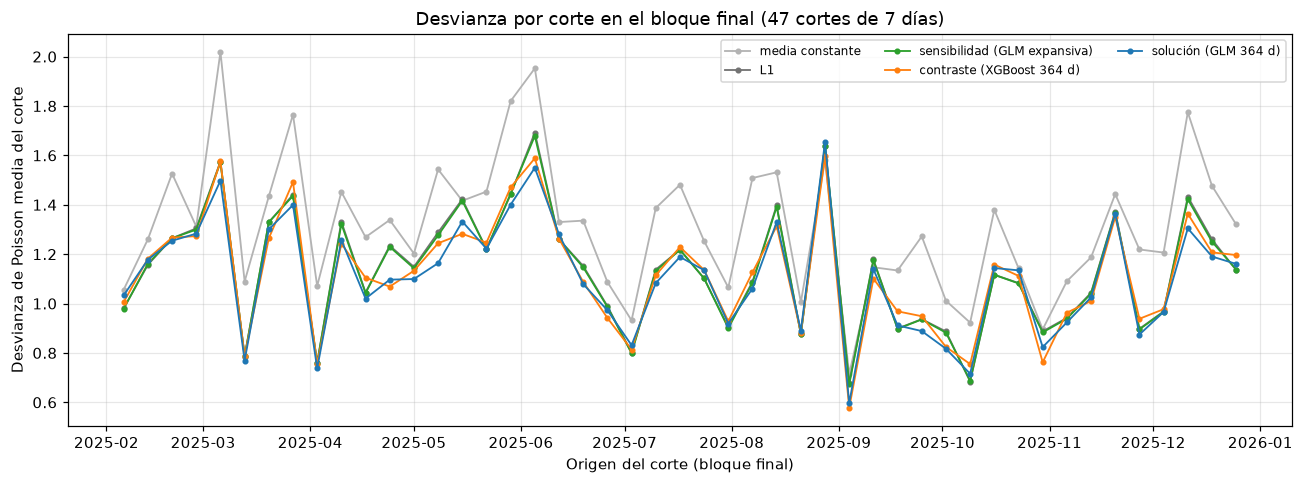

  guardado: experiments\evaluacion_final\figuras\fig2_desvianza_por_municipio.png


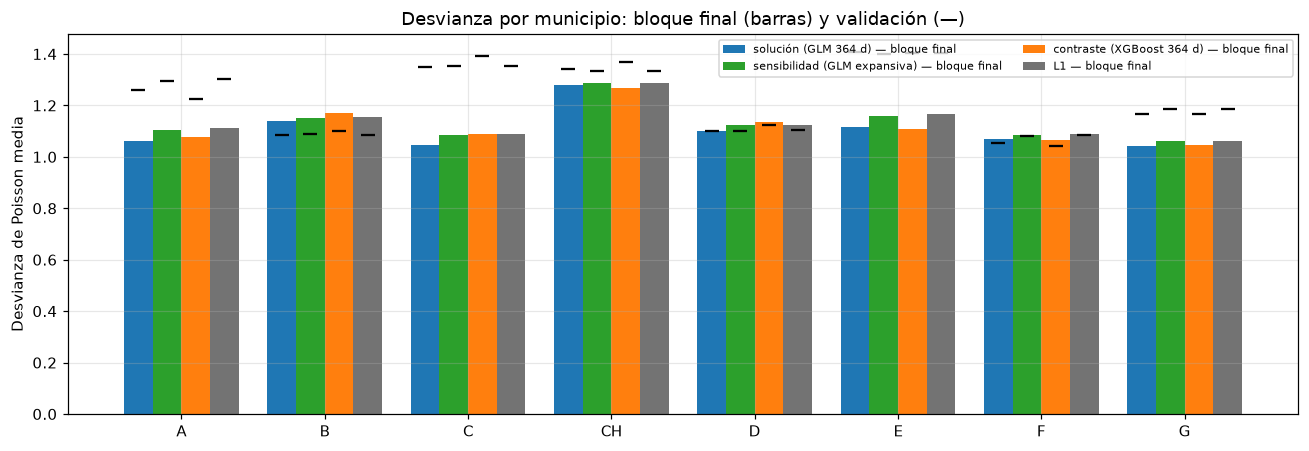

  guardado: experiments\evaluacion_final\figuras\fig3_total_semanal.png


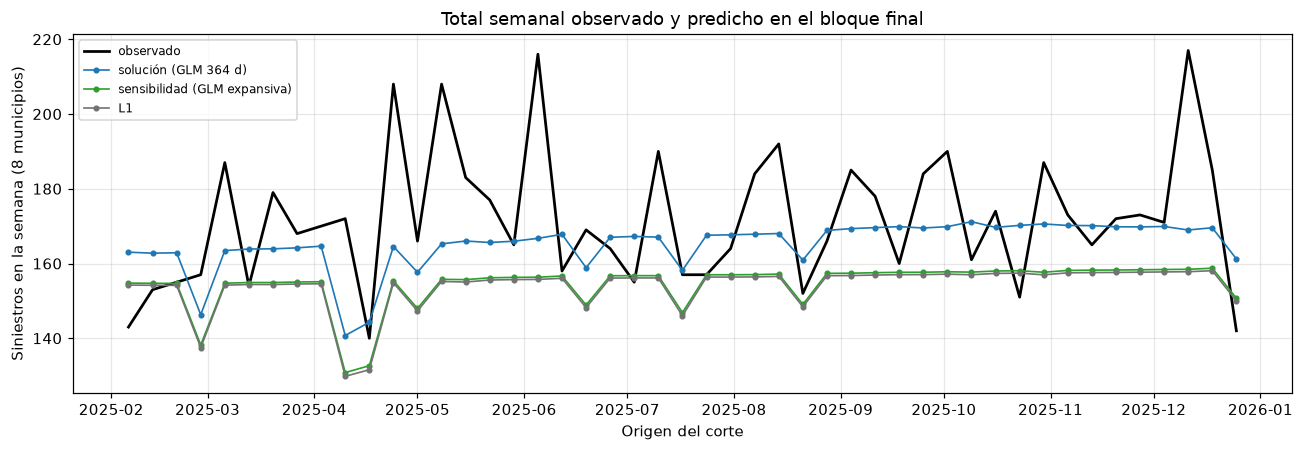

  guardado: experiments\evaluacion_final\figuras\fig4_calibracion_y_residuos.png


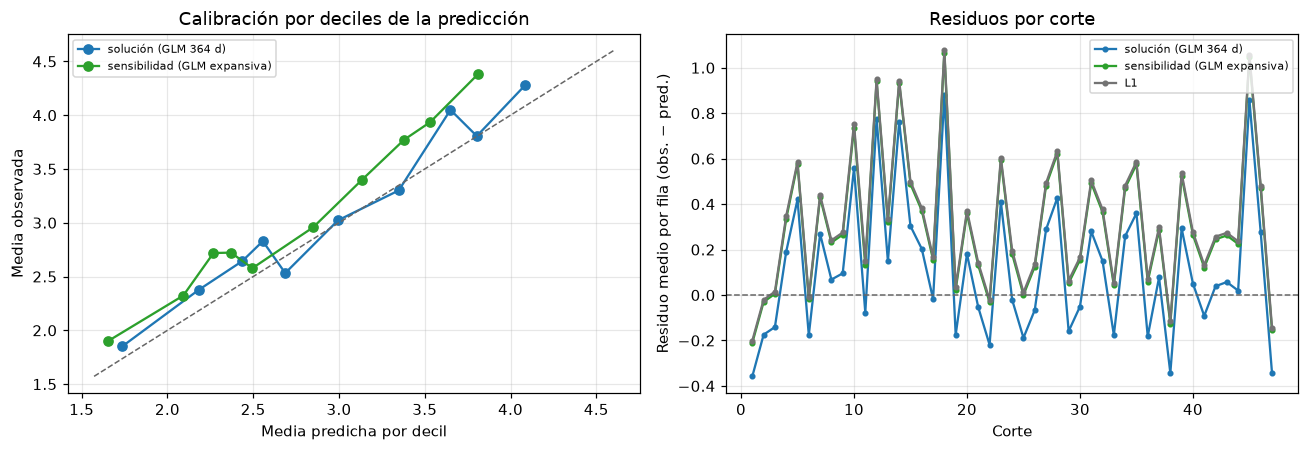

  guardado: experiments\evaluacion_final\figuras\fig5_cobertura_intervalos.png


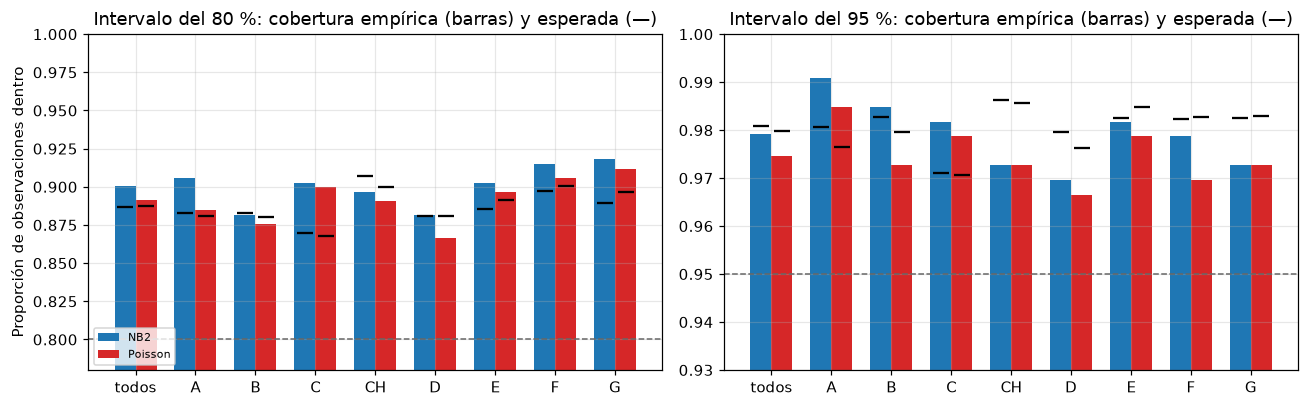

In [16]:
COLORES = {SOLUCION: "C0", SENSIBILIDAD: "C2", CONTRASTE: "C1", L1: "0.45", MEDIA: "0.7", L0: "C4"}
ETIQ = {SOLUCION: "solución (GLM 364 d)", SENSIBILIDAD: "sensibilidad (GLM expansiva)", CONTRASTE: "contraste (XGBoost 364 d)",
        L1: "L1", MEDIA: "media constante", L0: "L0 (8 semanas)"}
fechas_corte = pred_fin[SOLUCION].groupby("corte")["origen"].first()

# fig1: desvianza por corte
fig, ax = plt.subplots(figsize=(12, 4.5))
for n in (MEDIA, L1, SENSIBILIDAD, CONTRASTE, SOLUCION):
    ax.plot(fechas_corte.to_numpy(), pc[n].to_numpy(), "o-", ms=3, lw=1.2, color=COLORES[n], label=ETIQ[n])
ax.set_ylabel("Desvianza de Poisson media del corte")
ax.set_xlabel("Origen del corte (bloque final)")
ax.set_title("Desvianza por corte en el bloque final (47 cortes de 7 días)")
ax.legend(fontsize=8, ncol=3)
fig.tight_layout()
guardar_figura(fig, "fig1_desvianza_por_corte.png")
plt.show()

# fig2: desvianza por municipio en el bloque final y en validación
fig, ax = plt.subplots(figsize=(12, 4.2))
ancho = 0.2
for k, n in enumerate((SOLUCION, SENSIBILIDAD, CONTRASTE, L1)):
    t = por_mun[por_mun["modelo"] == n].set_index("zona_id").loc[mod.MUNICIPIOS]
    x = np.arange(8) + (k - 1.5) * ancho
    ax.bar(x, t["desvianza_poisson"], width=ancho, color=COLORES[n], label=ETIQ[n] + " — bloque final")
    ax.scatter(x, t["desvianza_validacion"], marker="_", s=90, color="k", zorder=3)
ax.set_xticks(range(8), [m.removeprefix("MUNICIPIO ") for m in mod.MUNICIPIOS])
ax.set_ylabel("Desvianza de Poisson media")
ax.set_title("Desvianza por municipio: bloque final (barras) y validación (—)")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
guardar_figura(fig, "fig2_desvianza_por_municipio.png")
plt.show()

# fig3: total semanal observado y predicho (8 municipios)
fig, ax = plt.subplots(figsize=(12, 4.2))
obs_sem = pred_fin[SOLUCION].groupby("corte")["n_siniestros"].sum()
ax.plot(fechas_corte.to_numpy(), obs_sem.to_numpy(), "k-", lw=1.8, label="observado")
for n in (SOLUCION, SENSIBILIDAD, L1):
    ax.plot(fechas_corte.to_numpy(), pred_fin[n].groupby("corte")["pred"].sum().to_numpy(), "o-", ms=3, lw=1.1,
            color=COLORES[n], label=ETIQ[n])
ax.set_ylabel("Siniestros en la semana (8 municipios)")
ax.set_xlabel("Origen del corte")
ax.set_title("Total semanal observado y predicho en el bloque final")
ax.legend(fontsize=8)
fig.tight_layout()
guardar_figura(fig, "fig3_total_semanal.png")
plt.show()

# fig4: calibración por deciles y residuos por corte
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for n in (SOLUCION, SENSIBILIDAD):
    t = deciles[deciles["modelo"] == n]
    axes[0].plot(t["media_predicha"], t["media_observada"], "o-", color=COLORES[n], label=ETIQ[n])
lim = [deciles[["media_predicha", "media_observada"]].min().min() * 0.95, deciles[["media_predicha", "media_observada"]].max().max() * 1.05]
axes[0].plot(lim, lim, color="0.4", ls="--", lw=1)
axes[0].set_xlabel("Media predicha por decil")
axes[0].set_ylabel("Media observada")
axes[0].set_title("Calibración por deciles de la predicción")
axes[0].legend(fontsize=7)
for n in (SOLUCION, SENSIBILIDAD, L1):
    t = residuos[residuos["modelo"] == n]
    axes[1].plot(t["corte"], t["residuo_medio"], "o-", ms=3, color=COLORES[n], label=ETIQ[n])
axes[1].axhline(0, color="0.4", ls="--", lw=1)
axes[1].set_xlabel("Corte")
axes[1].set_ylabel("Residuo medio por fila (obs. − pred.)")
axes[1].set_title("Residuos por corte")
axes[1].legend(fontsize=7)
fig.tight_layout()
guardar_figura(fig, "fig4_calibracion_y_residuos.png")
plt.show()

# fig5: cobertura de los intervalos de la solución
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, nivel in zip(axes, mod.NIVELES_INTERVALO):
    for k, (tipo, color) in enumerate(zip(TIPOS, ("C0", "C3"))):
        t = cobertura[(cobertura["intervalo"] == tipo) & (cobertura["nivel_nominal"] == nivel)]
        x = np.arange(len(t)) + (k - 0.5) * 0.35
        ax.bar(x, t["cobertura_empirica"], width=0.35, color=color, label=tipo.split(";")[0].split(" (")[0])
        ax.scatter(x, t["cobertura_esperada_por_el_modelo"], marker="_", s=120, color="k", zorder=3)
    ax.axhline(nivel / 100, color="0.4", ls="--", lw=1)
    ax.set_xticks(range(len(t)), [m.replace("MUNICIPIO ", "") for m in t["municipio"]])
    _t = cobertura[cobertura["nivel_nominal"] == nivel]
    ax.set_ylim(min(_t["cobertura_empirica"].min(), _t["cobertura_esperada_por_el_modelo"].min(), nivel / 100) - 0.02, 1.0)
    ax.set_title(f"Intervalo del {nivel} %: cobertura empírica (barras) y esperada (—)")
axes[0].set_ylabel("Proporción de observaciones dentro")
axes[0].legend(fontsize=7, loc="lower left")
fig.tight_layout()
guardar_figura(fig, "fig5_cobertura_intervalos.png")
plt.show()

## 12. Índice de artefactos

Las lecturas de los resultados están en `documentacion/resumen_evaluacion_final.md`. Este notebook no se edita después de ejecutarse: si
hace falta corregir algo, se corrige y se reejecuta completo, y `registro_ejecucion.csv` tiene que reproducirse exactamente.

In [17]:
indice = pd.DataFrame(sorted([f"tablas/{p.name}" for p in DIR_TABLAS.glob("*.csv")] +
                             [f"figuras/{p.name}" for p in DIR_FIGURAS.glob("*.png")] +
                             ["predicciones_bloque_final.csv", "registro_ejecucion.csv"]), columns=["artefacto"])
guardar_tabla(indice, "20_artefactos.csv")
indice

  guardado: experiments\evaluacion_final\tablas\20_artefactos.csv (27 filas)


,artefacto
0,figuras/fig1_desvianza_por_corte.png
1,figuras/fig2_desvianza_por_municipio.png
2,figuras/fig3_total_semanal.png
3,figuras/fig4_calibracion_y_residuos.png
4,figuras/fig5_cobertura_intervalos.png
5,predicciones_bloque_final.csv
6,registro_ejecucion.csv
7,tablas/00_entorno.csv
8,tablas/01_verificacion_solucion_fijada.csv
9,tablas/02_control_validacion.csv
